In [11]:
import os
import json
from pathlib import Path
import pandas as pd
#import re
import unstudied_gene_tools as usg
from matplotlib import pyplot as plt

# Extract alphafold data and metadata for gois including rea1, atp23, mug16, cog3 and human orthologs. 

In [23]:
# Download AlphaFold metadata and PDB files for each protein in the input file 

goi_file = os.path.normpath("G:/My Drive/Crick_LMS/projects/a_unstudied_genes/Melania_rea1/goi/goi_list.tsv")
output_dir = os.path.normpath("G:/My Drive/Crick_LMS/projects/a_unstudied_genes/Melania_rea1/goi/alphafold_downloads")

usg.alphafold_download(goi_file, output_dir)

AlphaFold PDB Downloader
Reading sequences from: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\goi\goi_list.tsv
Output directory:       G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\goi\alphafold_downloads

  ✓ Saved metadata to G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\goi\alphafold_downloads\model_metadata\metadata_HGNC27012_C22orf39_Q6P5X5.json
  ✓ Saved PDB to G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\goi\alphafold_downloads\pdb\HGNC27012_C22orf39_Q6P5X5.pdb
  ✓ Saved metadata to G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\goi\alphafold_downloads\model_metadata\metadata_HGNC29452_ATP23_Q9Y6H3.json
  ✓ Saved PDB to G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\goi\alphafold_downloads\pdb\HGNC29452_ATP23_Q9Y6H3.pdb
  ✓ Saved metadata to G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\goi\alphafold_downloads\model_metadata\metadata_SPAC227.17c_rea1_Q9UTC2.json
  ✓ Sa

# CIF File Parser for Protein Structure Data

Extract atom site data from AlphaFold3 predicted protein complexes and save as CSV files.

Input files defined in file_dict below and output saved to output_dir


In [2]:
# Cif Files to parse:

base_dir = os.path.normpath("G:/My Drive/Crick_LMS/projects/a_unstudied_genes/Melania_rea1/ppis/af3")
    
file_dict = {
    ("C22orf29", "ATP23") : base_dir + os.sep + os.path.normpath("human_rea1_atp23_2026_04_23_16_10/fold_human_rea1_atp23_2026_04_23_16_10_model_0.cif"),    
    ("Rea1","Atp23") : base_dir + os.sep + os.path.normpath("rea1_atp23_2025_11_26_13_55/fold_2025_11_26_13_55_spac227_17c_spcc320_12_model_0.cif"),
    ("Rea1","Rib3") : base_dir + os.sep + os.path.normpath("rea1_rib3_2025_11_26_13_27/fold_2025_11_26_13_27_spac227_17c_spbc23e6_06c_model_0.cif"),
    ("Cox1","Cox2") : base_dir + os.sep + os.path.normpath("cox1_cox2_2025_11_26_12_03/fold_cox1_cox2_2025_11_26_12_03_model_0.cif"),
    ("Rea1","Yta12") : base_dir +os.sep + os.path.normpath("rea1_yta12_2026_04_24_11_03/fold_rea1_yta12_2026_04_24_11_03_model_0.cif"),
    ("UNC50","COG3") : base_dir + os.sep + os.path.normpath("human_unc50_cog3_2026_04_24_11_06/fold_human_unc50_cog3_2026_04_24_11_06_model_0.cif"),
    ("Mug16","Cog3") : base_dir + os.sep + os.path.normpath("mug16_cog3_2026_04_24_11_05/fold_mug16_cog3_2026_04_24_11_05_model_0.cif")
}


In [5]:
# Parse each complex individually and save to per-complex extracted_metadata directories
# This ensures proteins from multiple complexes maintain their context-specific pLDDT scores
# Also calculates pLDDT statistics for each complex and saves to a per-complex statistics file for later aggregation    

print("="*70)
print("PARSING COMPLEXES AND EXTRACTING TO PER-COMPLEX DIRECTORIES")
print("="*70)

# Dictionary to track all complex statistics for later aggregation
all_complex_stats = {
    'Complex': [],
    'Protein_A': [],
    'Protein_B': [],
    'Total_Atoms': [],
    'Overall_Avg_pLDDT': [],
    'Overall_Min_pLDDT': [],
    'Overall_Max_pLDDT': [],
    # Per-protein statistics
    'Protein_A_Atoms': [],
    'Protein_A_Avg_pLDDT': [],
    'Protein_A_Min_pLDDT': [],
    'Protein_A_Max_pLDDT': [],
    'Protein_B_Atoms': [],
    'Protein_B_Avg_pLDDT': [],
    'Protein_B_Min_pLDDT': [],
    'Protein_B_Max_pLDDT': []
}

for (protein_a_name, protein_b_name), cif_file in file_dict.items():
    complex_name = f"{protein_a_name}_{protein_b_name}"
    print(f"\n📁 Processing: {complex_name}")
    print(f"   CIF file: {cif_file}")
    
    try:
        # Derive the complex folder path from the CIF file path
        cif_path = Path(cif_file)
        complex_folder = cif_path.parent
        output_dir = complex_folder / "extracted_metadata"
        
        print(f"   Output dir: {output_dir}")
        
        # Create output directory
        output_dir.mkdir(parents=True, exist_ok=True)
        
        # Parse the CIF file
        df_complex = usg.parse_cif_atom_site(cif_file)
        print(f"   ✓ Parsed {len(df_complex)} atoms from complex")
        
        # Extract chain A (first protein)
        df_chain_a = df_complex[df_complex['auth_asym_id'] == 'A'].copy()
        df_chain_b = df_complex[df_complex['auth_asym_id'] == 'B'].copy()
        
        # Save chain A
        if len(df_chain_a) > 0:
            file_a = output_dir / f"{protein_a_name}_pdb_data.csv"
            df_chain_a.to_csv(file_a, index=False)
            print(f"   ✓ Saved chain A ({protein_a_name}): {len(df_chain_a)} atoms → {file_a.name}")
        else:
            print(f"   ⚠ Warning: No atoms found for chain A ({protein_a_name})")
        
        # Save chain B
        if len(df_chain_b) > 0:
            file_b = output_dir / f"{protein_b_name}_pdb_data.csv"
            df_chain_b.to_csv(file_b, index=False)
            print(f"   ✓ Saved chain B ({protein_b_name}): {len(df_chain_b)} atoms → {file_b.name}")
        else:
            print(f"   ⚠ Warning: No atoms found for chain B ({protein_b_name})")
        
        # Calculate pLDDT statistics for this complex
        if len(df_chain_a) > 0 and len(df_chain_b) > 0:
            df_combined = pd.concat([df_chain_a, df_chain_b], ignore_index=True)
            plddt_scores = pd.to_numeric(df_combined['B_iso_or_equiv'], errors='coerce')
            
            # Overall statistics
            overall_avg = plddt_scores.mean()
            overall_min = plddt_scores.min()
            overall_max = plddt_scores.max()
            total_atoms = len(df_combined)
            
            # Protein A statistics
            plddt_a = pd.to_numeric(df_chain_a['B_iso_or_equiv'], errors='coerce')
            a_atoms = len(df_chain_a)
            a_avg = plddt_a.mean()
            a_min = plddt_a.min()
            a_max = plddt_a.max()
            
            # Protein B statistics
            plddt_b = pd.to_numeric(df_chain_b['B_iso_or_equiv'], errors='coerce')
            b_atoms = len(df_chain_b)
            b_avg = plddt_b.mean()
            b_min = plddt_b.min()
            b_max = plddt_b.max()
            
            # Store in aggregation dictionary
            all_complex_stats['Complex'].append(complex_name)
            all_complex_stats['Protein_A'].append(protein_a_name)
            all_complex_stats['Protein_B'].append(protein_b_name)
            all_complex_stats['Total_Atoms'].append(total_atoms)
            all_complex_stats['Overall_Avg_pLDDT'].append(overall_avg)
            all_complex_stats['Overall_Min_pLDDT'].append(overall_min)
            all_complex_stats['Overall_Max_pLDDT'].append(overall_max)
            # Per-protein statistics
            all_complex_stats['Protein_A_Atoms'].append(a_atoms)
            all_complex_stats['Protein_A_Avg_pLDDT'].append(a_avg)
            all_complex_stats['Protein_A_Min_pLDDT'].append(a_min)
            all_complex_stats['Protein_A_Max_pLDDT'].append(a_max)
            all_complex_stats['Protein_B_Atoms'].append(b_atoms)
            all_complex_stats['Protein_B_Avg_pLDDT'].append(b_avg)
            all_complex_stats['Protein_B_Min_pLDDT'].append(b_min)
            all_complex_stats['Protein_B_Max_pLDDT'].append(b_max)
            
            # Save per-complex statistics file
            complex_stats_df = pd.DataFrame({
                'Protein_A': [protein_a_name],
                'Protein_B': [protein_b_name],
                'Protein_A_Atoms': [a_atoms],
                'Protein_A_Avg_pLDDT': [a_avg],
                'Protein_A_Min_pLDDT': [a_min],
                'Protein_A_Max_pLDDT': [a_max],
                'Protein_B_Atoms': [b_atoms],
                'Protein_B_Avg_pLDDT': [b_avg],
                'Protein_B_Min_pLDDT': [b_min],
                'Protein_B_Max_pLDDT': [b_max],
                'Total_Atoms': [total_atoms],
                'Overall_Avg_pLDDT': [overall_avg],
                'Overall_Min_pLDDT': [overall_min],
                'Overall_Max_pLDDT': [overall_max]
            })
            
            stats_file = output_dir / "plddt_statistics.csv"
            complex_stats_df.to_csv(stats_file, index=False)
            print(f"   ✓ Saved pLDDT statistics: {overall_avg:.2f} (overall avg) → {stats_file.name}")
            print(f"      {protein_a_name}: {a_avg:.2f} avg | {protein_b_name}: {b_avg:.2f} avg")
        
    except Exception as e:
        print(f"   ✗ Error processing complex: {e}")

print(f"\n{'='*70}")
print(f"Extraction complete for {len(all_complex_stats['Complex'])} complexes")
print(f"{'='*70}")

PARSING COMPLEXES AND EXTRACTING TO PER-COMPLEX DIRECTORIES

📁 Processing: C22orf29_ATP23
   CIF file: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\ppis\af3\human_rea1_atp23_2026_04_23_16_10\fold_human_rea1_atp23_2026_04_23_16_10_model_0.cif
   Output dir: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\ppis\af3\human_rea1_atp23_2026_04_23_16_10\extracted_metadata
   ✓ Parsed 2857 atoms from complex
   ✓ Saved chain A (C22orf29): 884 atoms → C22orf29_pdb_data.csv
   ✓ Saved chain B (ATP23): 1973 atoms → ATP23_pdb_data.csv
   ✓ Saved pLDDT statistics: 82.70 (overall avg) → plddt_statistics.csv
      C22orf29: 87.08 avg | ATP23: 80.73 avg

📁 Processing: Rea1_Atp23
   CIF file: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\ppis\af3\rea1_atp23_2025_11_26_13_55\fold_2025_11_26_13_55_spac227_17c_spcc320_12_model_0.cif
   Output dir: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\ppis\af3\rea1_atp23_2025_11_26_13_55\extracted_metad

# Download pdbs and metadata for proteins for the rea1 interactor screen from alphafold

In [8]:
# Download AlphaFold metadata and PDB files for each protein in the input file 

rea1_interactor_candidates = os.path.normpath("G:/My Drive/Crick_LMS/projects/a_unstudied_genes/Melania_rea1/rea1_interaction_screen/rea1_interactor_candidates.tsv")
output_dir = os.path.normpath("G:/My Drive/Crick_LMS/projects/a_unstudied_genes/Melania_rea1/rea1_interaction_screen/alphafold_downloads")

usg.alphafold_download(rea1_interactor_candidates, output_dir)

AlphaFold PDB Downloader
Reading sequences from: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\rea1_interaction_screen\rea1_interactor_candidates.tsv
Output directory:       G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\rea1_interaction_screen\alphafold_downloads

  ✓ Saved metadata to G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\rea1_interaction_screen\alphafold_downloads\model_metadata\metadata_SPBC23E6.06c_rib3_O60181.json
  ✓ Saved PDB to G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\rea1_interaction_screen\alphafold_downloads\pdb\SPBC23E6.06c_rib3_O60181.pdb
  ✓ Saved metadata to G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\rea1_interaction_screen\alphafold_downloads\model_metadata\metadata_SPBC409.13_rib4_Q9UUB1.json
  ✓ Saved PDB to G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\rea1_interaction_screen\alphafold_downloads\pdb\SPBC409.13_rib4_Q9UUB1.pdb
  ✓ Saved metadata to G:\My Dri

In [9]:
# Define paths
metadata_dir = os.path.normpath("G:/My Drive/Crick_LMS/projects/a_unstudied_genes/Melania_rea1/rea1_interaction_screen/alphafold_downloads/model_metadata")
fasta_output = os.path.normpath("G:/My Drive/Crick_LMS/projects/a_unstudied_genes/Melania_rea1/rea1_interaction_screen/alphafold_downloads/sequences.fasta")

# Write FASTA file
with open(fasta_output, 'w') as fasta_file:
    # Iterate through all JSON files in the metadata directory
    json_files = sorted(Path(metadata_dir).glob('metadata_*.json'))
    
    for json_file in json_files:
        try:
            # Parse filename: metadata_{systematic_id}_{gene_name}_{uniprot_id}.json
            filename = json_file.stem  # Remove .json extension
            parts = filename.split('_')
            
            # Extract components
            # Format: metadata_SYSTEMATIC_ID_GENE_NAME_UNIPROT_ID
            systematic_id = parts[1]
            gene_name = parts[2]
            uniprot_id = parts[3]
            
            # Read JSON file
            with open(json_file, 'r') as f:
                metadata = json.load(f)
            
            # Extract sequence (it should be a list with at least one entry)
            if isinstance(metadata, list) and len(metadata) > 0:
                sequence = metadata[0].get('sequence', '')
            else:
                sequence = metadata.get('sequence', '')
            
            if sequence:
                # Write FASTA entry
                fasta_header = f">{uniprot_id} systematic_id={systematic_id} gene_name={gene_name}"
                fasta_file.write(fasta_header + '\n')
                fasta_file.write(sequence + '\n')
                print(f"✓ Added {uniprot_id} ({systematic_id} - {gene_name})")
            else:
                print(f"⚠ No sequence found for {json_file.name}")
                
        except Exception as e:
            print(f"✗ Error processing {json_file.name}: {e}")

print(f"\n✓ FASTA file saved to: {fasta_output}")
print(f"Total proteins processed: {len(json_files)}")

✓ Added Q09864 (SPAC12G12.04 - mcp60)
✓ Added Q10481 (SPAC17C9.09c - tim13)
✓ Added Q9UTC2 (SPAC227.17c - rea1)
✓ Added O13931 (SPAC23C4.11 - atp18)
✓ Added Q09892 (SPAC24B11.06c - sty1)
✓ Added O13962 (SPAC24C9.02c - cyt2)
✓ Added Q10167 (SPAC26A3.14c - atg44)
✓ Added O14033 (SPAC29B12.12 - hot13)
✓ Added P87127 (SPAC3A12.12 - atp11)
✓ Added O14144 (SPAC3G6.08 - erv1)
✓ Added G2TRJ8 (SPAC4F10.22 - cmc4)
✓ Added Q09836 (SPAC4G8.11c - atp10)
✓ Added P33075 (SPAC4G9.03 - adk1)
✓ Added P87059 (SPAC57A10.11c - mia40)
✓ Added Q10307 (SPAC6C3.02c - mix17)
✓ Added P49740 (SPAC806.07 - ndk1)
✓ Added P28758 (SPAC821.10c - sod1)
✓ Added G2TRN2 (SPAC926.10 - ina22)
✓ Added Q9UT07 (SPAP8A3.10 - ups1)
✓ Added O42908 (SPBC119.17 - cym1)
✓ Added Q96VG1 (SPBC119.18 - mdm35)
✓ Added P87320 (SPBC1718.06 - msp1)
✓ Added O74347 (SPBC21D10.07 - cmc2)
✓ Added O60181 (SPBC23E6.06c - rib3)
✓ Added G2TRP6 (SPBC24C6.13 - coa6)
✓ Added O74794 (SPBC26H8.12 - cyc3)
✓ Added Q9P7Z7 (SPBC26H8.14c - cox17)
✓ Added O74

In [ ]:
# Standardize file naming conventions in AF3 PPI analysis folders

base_path = r"G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\ppis\af3"

print("="*70)
print("CHECKING PATH ACCESSIBILITY")
print("="*70)
print(f"Base path: {base_path}")

# Check if base path exists
if not Path(base_path).exists():
    print(f"✗ Base path does not exist: {base_path}")
    print("Cannot proceed with renaming.")
else:
    print(f"✓ Base path exists")
    bb
    # List directories in the base path
    try:
        print("\nDirectories found in base path:")
        dirs = [d.name for d in Path(base_path).iterdir() if d.is_dir()]
        for d in dirs:
            print(f"  - {d}")
    except Exception as e:
        print(f"✗ Error listing directories: {e}")
        dirs = []
    
    # Define renaming rules: (directory_name, old_pattern, new_pattern)
    renaming_rules = [
        ("human_rea1_atp23_2026_04_23_16_10",      
         "fold_hu_rea1_atp23_2026_04_23_16_10", 
         "fold_2026_04_23_16_10_human_rea1_atp23"),
        
        ("cox1_cox2_2025_11_26_12_03",      
         "fold_2025_11_26_12_03_cox1_cox2_pombe_test", 
         "fold_2025_11_26_12_03_cox1_cox2"),
        
        ("rea1_atp23_2025_11_26_13_55", 
         "fold_2025_11_26_13_55_spac227_17c_spcc320_12_full_data_0", 
         "fold_rea1_atp23_2025_11_26_13_55"),
        
        ("rea1_rib3_2025_11_26_13_27", 
         "fold_2025_11_26_13_27_spac227_17c_spbc23e6_06c_full_data_0", 
         "fold_rea1_rib3_2025_11_26_13_27"),
    ]
    
    print("\n" + "="*70)
    print("FILE RENAMING SUMMARY")
    print("="*70)
    
    total_files = 0
    for dir_name, old_pattern, new_pattern in renaming_rules:
        dir_path = Path(base_path) / dir_name
        
        print(f"\n📁 Processing: {dir_name}")
        
        # Verify directory exists
        if not dir_path.exists():
            print(f"   ✗ Directory not found: {dir_path}")
            continue
        
        print(f"   Old pattern: {old_pattern}")
        print(f"   New pattern: {new_pattern}")
        
        # Find and rename files
        try:
            files_renamed = 0
            for file in dir_path.iterdir():
                if file.is_file() and old_pattern in file.name:
                    new_name = file.name.replace(old_pattern, new_pattern)
                    new_file_path = file.parent / new_name
                    
                    file.rename(new_file_path)
                    print(f"   ✓ {file.name}")
                    print(f"     → {new_name}")
                    files_renamed += 1
            
            if files_renamed == 0:
                print(f"   ⚠ No files found matching pattern '{old_pattern}'")
            else:
                print(f"   ✓ Renamed {files_renamed} file(s)")
                total_files += files_renamed
        except Exception as e:
            print(f"   ✗ Error processing directory: {e}")
    
    print("\n" + "="*70)
    print(f"Renaming complete! Total files renamed: {total_files}")
    print("="*70)

FILE RENAMING SUMMARY

📁 Processing: human_rea1_atp23_2026_04_23_16_10
   Old pattern: fold_2026_04_23_16_10_human_rea1_atp23
   New pattern: fold_human_rea1_atp23_2026_04_23_16_10
   ✓ fold_2026_04_23_16_10_human_rea1_atp23_job_request.json
     → fold_human_rea1_atp23_2026_04_23_16_10_job_request.json
   ✓ fold_2026_04_23_16_10_human_rea1_atp23_model_0.cif
     → fold_human_rea1_atp23_2026_04_23_16_10_model_0.cif
   ✓ fold_2026_04_23_16_10_human_rea1_atp23_summary_confidences_0.json
     → fold_human_rea1_atp23_2026_04_23_16_10_summary_confidences_0.json
   ✓ fold_2026_04_23_16_10_human_rea1_atp23_full_data_0.json
     → fold_human_rea1_atp23_2026_04_23_16_10_full_data_0.json
   ✓ fold_2026_04_23_16_10_human_rea1_atp23_model_1.cif
     → fold_human_rea1_atp23_2026_04_23_16_10_model_1.cif
   ✓ fold_2026_04_23_16_10_human_rea1_atp23_summary_confidences_1.json
     → fold_human_rea1_atp23_2026_04_23_16_10_summary_confidences_1.json
   ✓ fold_2026_04_23_16_10_human_rea1_atp23_full_data_1

In [4]:
# Extract the range between the conserved cysteines for Rea1 and the human rea1 ortholog C22orf29 from the pdb and save to a new pdb. 

#Extract chain A, residues 1-100

chain = 'A'
residue_range = (34, 75)
input_pdb = os.path.normpath("G:/My Drive/Crick_LMS/projects/a_unstudied_genes/Melania_rea1/goi/alphafold_downloads/pdb/SPAC227.17c_rea1_Q9UTC2.pdb")
output_pdb = os.path.normpath("G:/My Drive/Crick_LMS/projects/a_unstudied_genes/Melania_rea1/goi/truncated_proteins/SPAC227.17c_rea1_Q9UTC2_truncated_{residue_range[0]}-{residue_range[1]}.pdb".format(residue_range=residue_range))

usg.extract_pdb_subset(input_pdb, chain, residue_range, output_pdb)


chain = 'A'
residue_range = (13, 52)
input_pdb = os.path.normpath("G:/My Drive/Crick_LMS/projects/a_unstudied_genes/Melania_rea1/goi/alphafold_downloads/pdb/HGNC27012_C22orf39_Q6P5X5.pdb")
output_pdb = os.path.normpath("G:/My Drive/Crick_LMS/projects/a_unstudied_genes/Melania_rea1/goi/truncated_proteins/HGNC27012_C22orf39_Q6P5X5_truncated_{residue_range[0]}-{residue_range[1]}.pdb".format(residue_range=residue_range))

usg.extract_pdb_subset(input_pdb, chain, residue_range, output_pdb)


✓ Extracted 368 atoms from chain A, residues 34-75
✓ Output saved to: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\goi\truncated_proteins\SPAC227.17c_rea1_Q9UTC2_truncated_34-75.pdb
✓ Extracted 344 atoms from chain A, residues 13-52
✓ Output saved to: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\Melania_rea1\goi\truncated_proteins\HGNC27012_C22orf39_Q6P5X5_truncated_13-52.pdb


344

In [2]:
# Extract metrics for all rea1 PPI models (best models ending in _0)

base_dir = Path(os.path.normpath("G:/My Drive/Crick_LMS/projects/a_unstudied_genes/Melania_rea1/ppis/af3"))
output_dir = base_dir / "extracted_metadata"

# Ensure output directory exists
output_dir.mkdir(parents=True, exist_ok=True)

print("="*70)
print("EXTRACTING AF3 PPI METRICS FOR REA1 INTERACTIONS")
print("="*70)

# Find all summary_confidences JSON files that:
# 1. Are in subdirectories of base_dir
# 2. Start with "fold_rea1_" (rea1 as protein A)
# 3. End with "_0.json" (best models only)

json_files = sorted(base_dir.glob("*/fold_rea1_*_summary_confidences_0.json"))

print(f"\nFound {len(json_files)} matching files:")
for f in json_files:
    print(f"  - {f.relative_to(base_dir)}")

# Extract metrics for each file
all_metrics = []
for json_file in json_files:
    try:
        print(f"\nProcessing: {json_file.name}")
        metrics = usg.extract_af3_ppi_metrics(str(json_file))
        all_metrics.append(metrics)
        print(f"  ✓ Extracted metrics for {metrics['Protein_A']} + {metrics['Protein_B']}")
    except Exception as e:
        print(f"  ✗ Error processing {json_file.name}: {e}")

# Build dataframe
if all_metrics:
    df_rea1_ppi = pd.DataFrame(all_metrics)
    
    # Save to CSV
    output_file = output_dir / "rea1_ppi_metadata.csv"
    df_rea1_ppi.to_csv(output_file, index=False)
    
    print(f"\n{'='*70}")
    print(f"✓ Saved {len(df_rea1_ppi)} interaction(s) to:")
    print(f"  {output_file}")
    print(f"{'='*70}")
    print(f"\nDataframe shape: {df_rea1_ppi.shape}")
    print(f"Columns: {list(df_rea1_ppi.columns)}")
else:
    print("\n✗ No metrics extracted - no matching files found")

EXTRACTING AF3 PPI METRICS FOR REA1 INTERACTIONS

Found 38 matching files:
  - rea1_adk1_2026_04_23_23_33\fold_rea1_adk1_2026_04_23_23_33_summary_confidences_0.json
  - rea1_atg44_2026_04_23_23_29\fold_rea1_atg44_2026_04_23_23_29_summary_confidences_0.json
  - rea1_atp10_2026_04_28_16_08\fold_rea1_atp10_2026_04_28_16_08_summary_confidences_0.json
  - rea1_atp11_2026_04_28_16_08\fold_rea1_atp11_2026_04_28_16_08_summary_confidences_0.json
  - rea1_atp18_2026_04_28_16_09\fold_rea1_atp18_2026_04_28_16_09_summary_confidences_0.json
  - rea1_atp23_2026_04_24_10_28\fold_rea1_atp23_2026_04_24_10_28_summary_confidences_0.json
  - rea1_cmc1_2026_04_24_10_27\fold_rea1_cmc1_2026_04_24_10_27_summary_confidences_0.json
  - rea1_cmc2_2026_04_24_10_19\fold_rea1_cmc2_2026_04_24_10_19_summary_confidences_0.json
  - rea1_cmc4_2026_04_23_23_32\fold_rea1_cmc4_2026_04_23_23_32_summary_confidences_0.json
  - rea1_coa4_2026_04_24_10_27\fold_rea1_coa4_2026_04_24_10_27_summary_confidences_0.json
  - rea1_coa6_2

High iPTM proteins (>0.5): ['atp23', 'mia40', 'sty1', 'ups1']
offset_dict (edit as needed):
{'atp23': (-20, 5), 'mia40': (0, -10), 'sty1': (-20, 5), 'ups1': (-20, 5)}


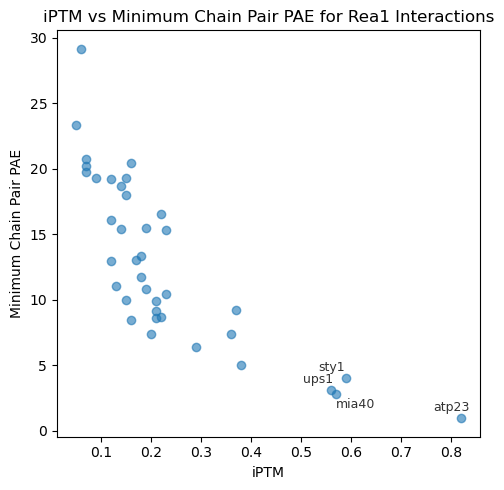

In [23]:
#Plot iPTM vs the minimum chain pair PAE to identify high-confidence interactions with low PAE and high iPTM scores.

# make a new column that takes the minimum of the two pae columns for A_B and B_A to get a single minimum pae value".
df_rea1_ppi["chain_pair_pae_AB_BA"] = df_rea1_ppi[["chain_pair_pae_min_A_B", "chain_pair_pae_min_B_A"]].min(axis=1)

plt.figure(figsize=(5,5))
plt.scatter(df_rea1_ppi["iptm"], df_rea1_ppi["chain_pair_pae_AB_BA"], alpha=0.6)

# Add labels for points with iPTM > 0.5
high_iptm_mask = df_rea1_ppi["iptm"] > 0.5

# Extract protein B names for high iPTM points and create offset dictionary
high_iptm_proteins = df_rea1_ppi[high_iptm_mask]["Protein_B"].tolist()
offset_dict = {protein: (-20, 5) for protein in high_iptm_proteins}
offset_dict["mia40"] = (0, -10)  # Example of custom offset for Atp23

print(f"High iPTM proteins (>0.5): {high_iptm_proteins}")
print(f"offset_dict (edit as needed):\n{offset_dict}")

for idx, row in df_rea1_ppi[high_iptm_mask].iterrows():
    protein_name = row["Protein_B"]
    offset = offset_dict[protein_name]
    plt.annotate(
        protein_name,
        xy=(row["iptm"], row["chain_pair_pae_AB_BA"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=9 ,
        alpha=0.8
    )

plt.xlabel("iPTM")
plt.ylabel("Minimum Chain Pair PAE")
plt.title("iPTM vs Minimum Chain Pair PAE for Rea1 Interactions")
plt.tight_layout()
plt.show()

In [9]:
#Screen for potential interactions between Rea1 and other mitochondrial inner membrane proteins.
df_rea1_ppi

,Protein_A,Protein_B,fraction_disordered,has_clash,iptm,num_recycles,ptm,ranking_score,chain_pair_pae_min_A_A,chain_pair_pae_min_A_B,chain_pair_pae_min_B_A,chain_pair_pae_min_B_B,chain_ptm_A,chain_ptm_B,chain_pair_pae_AB_BA
0,rea1,adk1,0.11,0.0,0.18,10.0,0.58,0.32,0.76,13.32,14.74,0.76,0.48,0.77,13.32
1,rea1,atg44,0.40,0.0,0.05,10.0,0.33,0.30,0.76,24.28,23.37,0.76,0.31,0.67,23.37
2,rea1,atp10,0.19,0.0,0.17,10.0,0.60,0.35,0.76,14.86,13.06,0.76,0.37,0.73,13.06
3,rea1,atp11,0.33,0.0,0.23,10.0,0.52,0.45,0.76,11.95,10.44,0.76,0.29,0.61,10.44
4,rea1,atp18,0.32,0.0,0.29,10.0,0.38,0.47,0.76,8.00,6.43,0.76,0.43,0.38,6.43
5,rea1,atp23,0.08,0.0,0.82,10.0,0.85,0.87,0.76,0.98,0.95,0.76,0.70,0.85,0.95
6,rea1,cmc1,0.35,0.0,0.22,10.0,0.35,0.42,0.76,8.98,8.69,0.76,0.34,0.50,8.69
7,rea1,cmc2,0.44,0.0,0.07,10.0,0.32,0.34,0.76,21.11,19.74,0.76,0.30,0.50,19.74
8,rea1,cmc4,0.14,0.0,0.38,10.0,0.45,0.46,0.76,6.81,5.00,0.76,0.26,0.77,5.00
9,rea1,coa4,0.37,0.0,0.16,10.0,0.31,0.38,0.76,10.47,8.43,0.76,0.32,0.49,8.43
